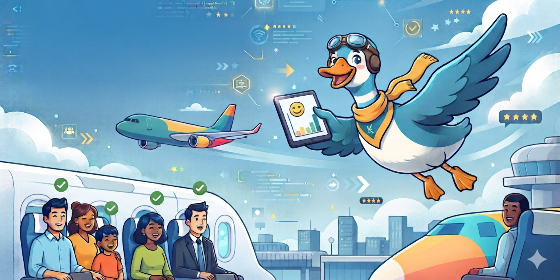

# Predicting Airline Satisfaction: Problem Definition

## 1. Competition
- Name: Kaggle Playground Series S6E10, Predicting Airline Satisfaction
- Link: https://www.kaggle.com/competitions/playground-series-s6e10

- Host: Kaggle (Yao Yan, Walter Reade, Elizabeth Park)

## 2. Business Problem
Predict whether an airline passenger will be satisfied, based on flight
details, passenger profile, and service ratings. Airlines can use this to
find which services drive satisfaction and where to improve.

## 3. ML Problem Type
- Supervised, binary classification
- Target: `satisfaction` (1 = satisfied, 0 = neutral or dissatisfied)
- Output required: a probability between 0 and 1 for each test row

## 4. Data
- **train.csv**: features + target (used to train and validate)
- **test.csv**: features only (used for the final predictions)
- **sample_submission.csv**: required format


## 5. Evaluation Metric
- ROC-AUC between predicted probabilities and true labels



# 1.Importing Data Files


In [1]:
import os
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

!pip install -q --upgrade kaggle
!kaggle competitions download -c playground-series-s6e10
!unzip -q playground-series-s6e10.zip -d data
!ls data

100% 15.1M/15.1M [00:00<00:00, 95.4MB/s]

sample_submission.csv  test.csv  train.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
sample_df = pd.read_csv(r"/content/data/sample_submission.csv")
# Format of output file to submit
sample_df
# {'id': [], 'satisfaction': []}

,id,satisfaction
0,699635,0.443573
1,699636,0.443573
2,699637,0.443573
3,699638,0.443573
4,699639,0.443573
...,...,...
299839,999474,0.443573
299840,999475,0.443573
299841,999476,0.443573
299842,999477,0.443573


In [4]:
test_df = pd.read_csv(r"/content/data/test.csv")
train_df = pd.read_csv(r"/content/data/train.csv")

In [5]:
test_df.head(5)

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
0,699635,25,1197,4,4,4,2,3,4,3,...,5,2,1,3,0,0.0,Female,disloyal Customer,Business travel,Eco
1,699636,36,829,5,5,5,5,5,4,5,...,2,4,3,5,0,0.0,Male,Loyal Customer,Business travel,Eco
2,699637,45,472,4,5,5,5,4,4,4,...,3,1,3,4,0,0.0,Male,Loyal Customer,Business travel,Eco
3,699638,45,762,2,2,2,5,3,2,3,...,4,4,4,3,0,0.0,Female,disloyal Customer,Business travel,Business
4,699639,34,594,1,2,1,1,2,1,2,...,4,2,1,2,0,0.0,Male,Loyal Customer,Personal Travel,Eco Plus


# 2.Data overview and performing EDA on dataset

In [6]:
train_df.head(5)

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [7]:
train_df.isnull().sum()
# Has null values inside the train dataset
# Arrival Delay Minutes has 292 missing values we can replace them with median of same column

,0
id,0
Age,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0
Ease of Online booking,0
Gate location,0
Food and drink,0
Online boarding,0
Seat comfort,0


In [8]:
median_mins = train_df["Arrival Delay in Minutes"].median()
train_df["Arrival Delay in Minutes"] = train_df["Arrival Delay in Minutes"].fillna(median_mins)

In [9]:
train_df["Arrival Delay in Minutes"].isnull().sum()
# No null valuesn


np.int64(0)

In [10]:
train_df.duplicated().sum()
# No Duplicated rows inside train data

np.int64(0)

In [11]:
train_df.shape
# Approx 700000 passenger's review

(699635, 23)

In [12]:
train_df.satisfaction

,satisfaction
0,False
1,True
2,False
3,False
4,False
...,...
699630,False
699631,False
699632,True
699633,True


In [13]:
train_df.drop(['id', 'satisfaction'], axis = 1)
# 21 Features/Input

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
0,36,694,4,4,4,3,1,4,1,1,...,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco
1,56,651,5,5,5,5,5,4,4,5,...,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business
2,31,1371,3,4,2,5,3,3,3,3,...,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco
3,10,1616,3,5,3,3,3,3,3,3,...,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco
4,23,481,3,4,3,4,5,3,5,5,...,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699630,57,612,2,1,1,1,1,3,3,2,...,2,2,2,4,0,0.0,Female,Loyal Customer,Business travel,Eco
699631,30,862,2,2,2,3,4,2,4,4,...,5,4,2,4,24,34.0,Female,disloyal Customer,Business travel,Eco
699632,49,3148,5,5,5,5,4,4,4,5,...,5,5,5,5,0,0.0,Male,Loyal Customer,Business travel,Business
699633,61,679,5,2,2,2,5,4,4,5,...,5,5,5,1,0,0.0,Female,Loyal Customer,Business travel,Eco


In [14]:
num_cols = train_df.select_dtypes(include="number").columns.tolist()
cat_cols = train_df.select_dtypes(include="object").columns.tolist()
num_cols.remove('id')
print("Numerical:", num_cols)
print("Categorical:", cat_cols)

print("\tNumber of numerical features are:", len(num_cols))
print("\tNumber of categorical features are:", len(cat_cols))


Numerical: ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']
Categorical: ['Gender', 'Customer Type', 'Type of Travel', 'Class']
	Number of numerical features are: 17
	Number of categorical features are: 4


In [15]:
print(train_df["satisfaction"].value_counts(normalize=True))

satisfaction
False    0.556427
True     0.443573
Name: proportion, dtype: float64


[Text(0, 0, '389296'), Text(0, 0, '310339')]

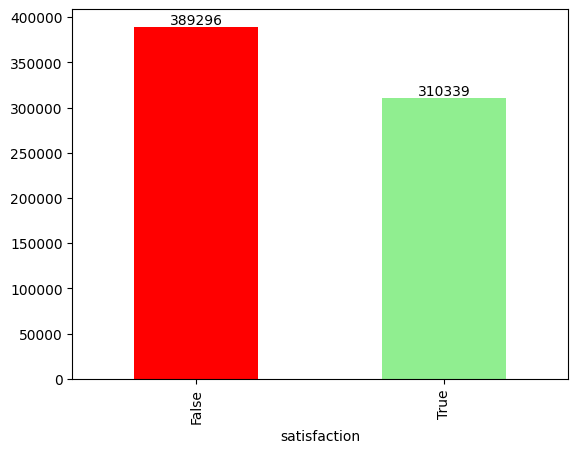

In [16]:
from typing import Annotated
ax = train_df.satisfaction.value_counts().plot(kind="bar", color=["red", 'lightgreen'])
ax.bar_label(ax.containers[0])
# majority of passengers are not satisfied


👇 Feature-Target analysis

Text(0, 0.5, 'Count')

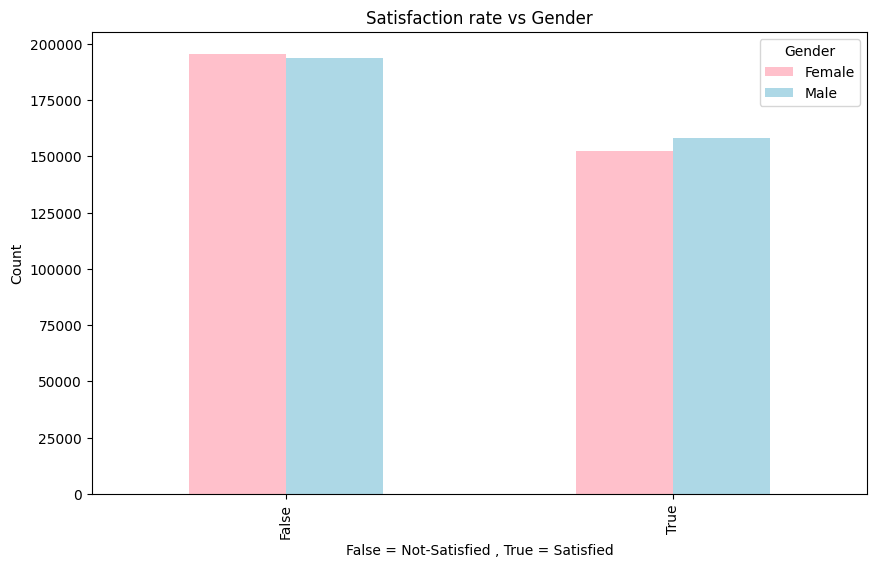

In [17]:
# Gender vs Satisfaction
pd.crosstab(index=train_df.satisfaction, columns = train_df.Gender).plot(kind = "bar",
                                                                         figsize = (10,6),
                                                                         color = ["pink", "lightblue"])
plt.title("Satisfaction rate vs Gender")
plt.xlabel("False = Not-Satisfied , True = Satisfied")
plt.ylabel("Count")


In [18]:
pd.crosstab(train_df["Gender"], train_df["satisfaction"], normalize = 'index')

satisfaction,False,True
Gender,,
Female,0.562006,0.437994
Male,0.550908,0.449092


- Gender has almost no effect on satisfaction, so it's a weak feature

In [19]:
# Class type vs satisfaction
pd.crosstab(train_df["Class"], train_df["satisfaction"], normalize = 'index')

satisfaction,False,True
Class,,
Business,0.274689,0.725311
Eco,0.832442,0.167558
Eco Plus,0.757820,0.242180


- Here we can clearly see that 72.5% Business of class passengers are satisfied.
- 83.2 % % Eco class passengers are not satisfied.
- Class is a strong feature for satisfaction prediction.

In [20]:
# Age vs Satisfaction
train_df.Age.describe()

,Age
count,699635.000000
mean,39.001928
std,13.800943
min,7.000000
25%,27.000000
50%,40.000000
75%,50.000000
max,85.000000


- Avg passenger's ge is 39.
- max is 85, min is 7

<Axes: ylabel='Density'>

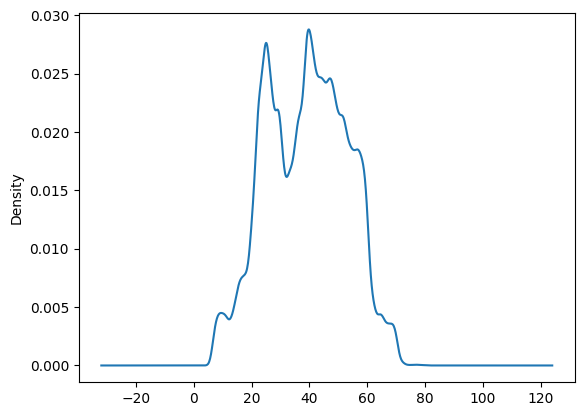

In [21]:
# Distribuation
train_df["Age"].plot(kind ="kde")

In [22]:
train_df.groupby("satisfaction")['Age'].mean()

,Age
satisfaction,
False,36.504131
True,42.135220


- Satisfied passengers are older on avg (42.1 years )

In [23]:
# Identifying strong numerical features for satisfaction prediction
cor_matrix = train_df[num_cols + ["satisfaction"]].corr()
cor_matrix

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
Age,1.000000,0.190709,0.043137,0.050863,0.043831,0.004095,0.048203,0.287612,0.229095,0.130684,0.096475,0.086409,-0.032758,0.069099,0.109591,-0.010311,-0.012870,0.202708
Flight Distance,0.190709,1.000000,0.046614,-0.036590,0.087908,0.019533,0.083711,0.310864,0.233666,0.206140,0.170306,0.194532,0.098368,0.104633,0.147663,-0.006978,-0.012242,0.370038
Inflight wifi service,0.043137,0.046614,1.000000,0.423833,0.771977,0.426632,0.145407,0.488734,0.165905,0.236276,0.133350,0.150859,0.115901,0.057094,0.166201,-0.015971,-0.020240,0.291275
Departure/Arrival time convenient,0.050863,-0.036590,0.423833,1.000000,0.550840,0.507193,0.006107,0.071405,0.008762,-0.007757,0.087505,0.005987,0.087606,0.110153,0.010944,-0.002309,-0.003153,-0.049185
Ease of Online booking,0.043831,0.087908,0.771977,0.550840,1.000000,0.580151,0.041581,0.403263,0.066317,0.079558,0.053308,0.090667,0.041568,0.018864,0.047616,-0.005112,-0.006844,0.190878
Gate location,0.004095,0.019533,0.426632,0.507193,0.580151,1.000000,0.011033,0.019974,0.017508,0.021315,-0.027713,0.002364,-0.006403,-0.043934,0.009139,0.003887,0.004765,0.022834
Food and drink,0.048203,0.083711,0.145407,0.006107,0.041581,0.011033,1.000000,0.263389,0.656050,0.656487,0.089891,0.053437,0.057830,0.092351,0.678229,-0.013869,-0.020034,0.218058
Online boarding,0.287612,0.310864,0.488734,0.071405,0.403263,0.019974,0.263389,1.000000,0.472677,0.374625,0.218875,0.184671,0.112208,0.210361,0.372450,-0.020194,-0.030739,0.559583
Seat comfort,0.229095,0.233666,0.165905,0.008762,0.066317,0.017508,0.656050,0.472677,1.000000,0.744750,0.194851,0.156010,0.111178,0.193581,0.762597,-0.016830,-0.027230,0.401488
Inflight entertainment,0.130684,0.206140,0.236276,-0.007757,0.079558,0.021315,0.656487,0.374625,0.744750,1.000000,0.425282,0.325798,0.394967,0.166283,0.750996,-0.020168,-0.031073,0.430755


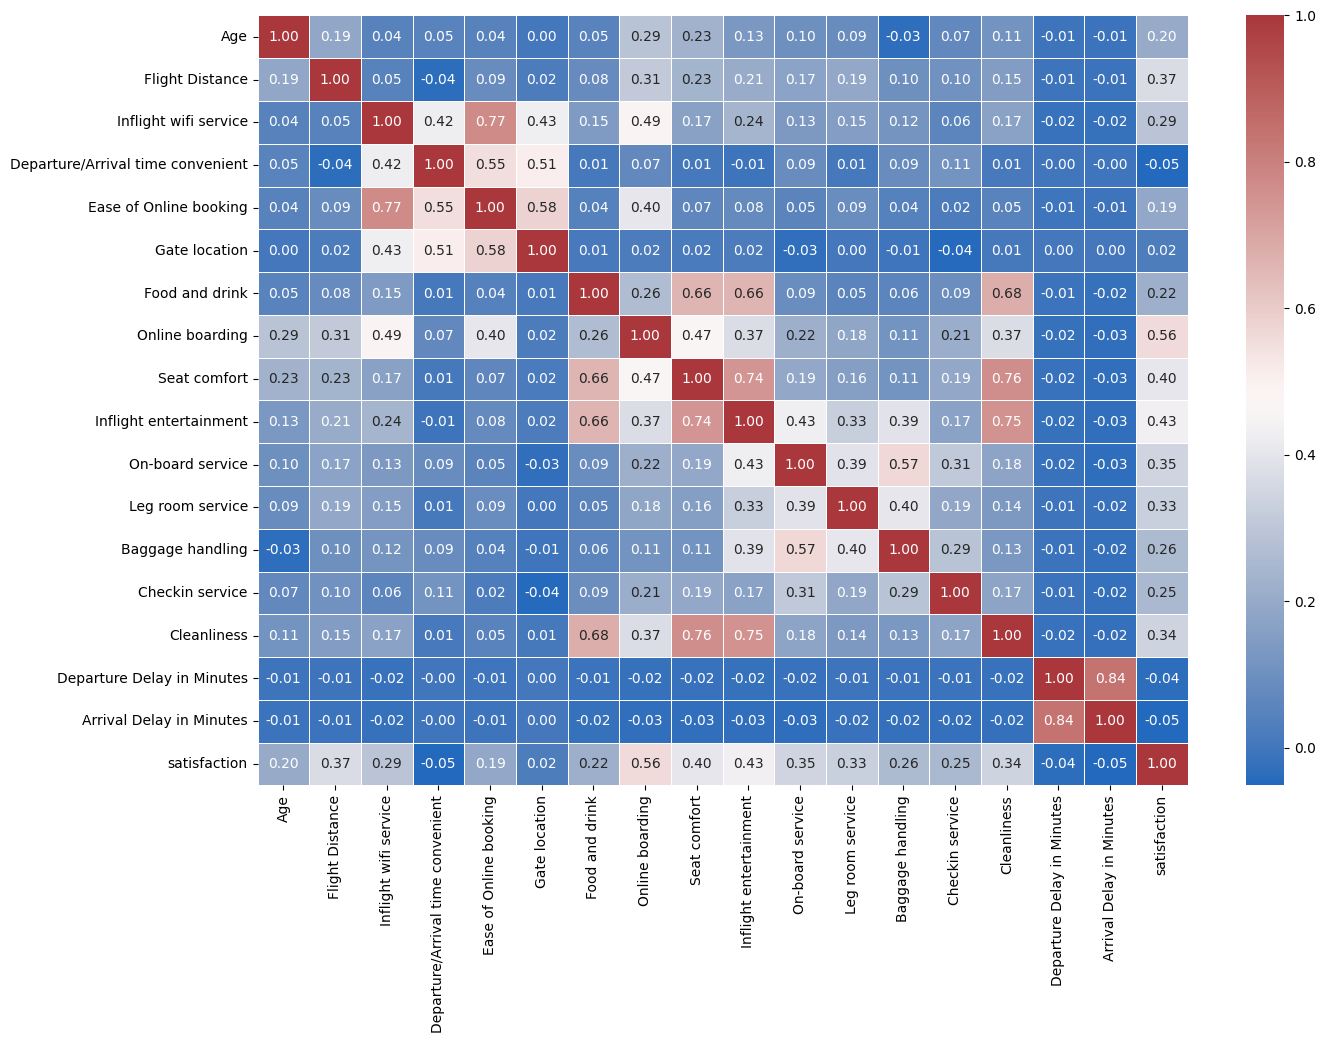

In [24]:
plt.figure(figsize=(15, 10))
sns.heatmap(cor_matrix,
            annot=True,
            linewidths=0.5,
            fmt= ".2f",
            cmap="vlag");

From the above correlation heatmap we can conclude that:
  - strong features are : `Online boarding`, `inflight entertainment`,
  `seat comfort`, `Flight Distance`


# 3.Data Preprocessing
  - Convert target to 0/1 ✅
  - Drop `id` from features, keeping only for submission ✅
  - Encode categoricals ✅

In [25]:
train_df["satisfaction"] = train_df["satisfaction"].astype(int)
train_df.head(5)

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,0


In [26]:
df = train_df.drop("id", axis = 1)
df.head(5)

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,36,694,4,4,4,3,1,4,1,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
1,56,651,5,5,5,5,5,4,4,5,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
2,31,1371,3,4,2,5,3,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
3,10,1616,3,5,3,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
4,23,481,3,4,3,4,5,3,5,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,0


In [27]:
X = df.drop("satisfaction", axis = 1) # Fetures
y = df["satisfaction"]

In [28]:
cat_cols

['Gender', 'Customer Type', 'Type of Travel', 'Class']

In [29]:
# One-hot encode categorical columns
X = pd.get_dummies(X, columns = cat_cols, drop_first= True, dtype=int)

In [30]:
print(X.columns.tolist())

['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender_Male', 'Customer Type_disloyal Customer', 'Type of Travel_Personal Travel', 'Class_Eco', 'Class_Eco Plus']


In [31]:
# Split in train and test data
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

In [32]:
X_train.isnull().sum()

,0
Age,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0
Ease of Online booking,0
Gate location,0
Food and drink,0
Online boarding,0
Seat comfort,0
Inflight entertainment,0


# 4.Selecting and training the Model

In [33]:
# Model 1
# Base model: LogisticRegresssion
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler # Scaling X_train
from sklearn.linear_model import LogisticRegression

log_model = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000)),
])

log_model.fit(X_train, y_train)

Pipeline(steps=[('scale', StandardScaler()),
                ('clf', LogisticRegression(max_iter=1000))])

In [34]:
print("Base model accuracy score: ",round(log_model.score(X_val, y_val),4))

Base model accuracy score:  0.8776


- Accuracy score of the Base model is : 87.7 %

In [35]:
from sklearn.metrics import roc_auc_score
val_proba = log_model.predict_proba(X_val)[:, 1]
print("Base model validation ROC-AUC:", round(roc_auc_score(y_val, val_proba), 4))

Base model validation ROC-AUC: 0.9214


In [36]:
# Model 2: RandomforestClassifier()
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=42,
)
rf_model.fit(X_train, y_train)

rf_proba = rf_model.predict_proba(X_val)[:, 1]
print("Random Forest validation ROC-AUC:", round(roc_auc_score(y_val, rf_proba), 4))

Random Forest validation ROC-AUC: 0.9561


In [37]:
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(y_val, rf_proba)

In [38]:
# Plotting ROC curve
def plot_roc_curve(fpr, tpr):
  """
  Plot a ROC curve given the false positive rate (fpr) and ture positive rate (tpr)
  of a model.
  """
  # Plot roc curve
  plt.plot(fpr, tpr, color = "orange", label = 'ROC')
  # Plot the line with no predective power (baseline)
  plt.plot([0,1],[0,1], color = "darkblue", linestyle = "--", label = "Guessing")

  # Customization the plot
  plt.xlabel("false positive rate (fpr)")
  plt.ylabel("True positive rate (tpr)")
  plt.title("Receiver Operating Characteristic (ROC) Curve")
  plt.legend()
  plt.show()


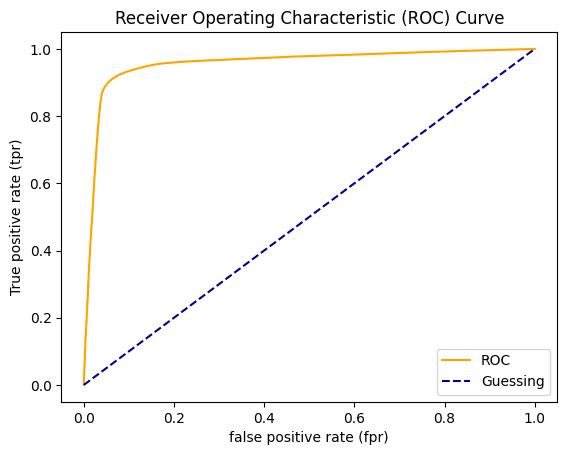

In [39]:
# ROC curver for Model 2 (rf_model) performance
plot_roc_curve(fpr,tpr)

# 5.Preprocessing on Test dataset for final submission


In [41]:
test_df.head(5)

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
0,699635,25,1197,4,4,4,2,3,4,3,...,5,2,1,3,0,0.0,Female,disloyal Customer,Business travel,Eco
1,699636,36,829,5,5,5,5,5,4,5,...,2,4,3,5,0,0.0,Male,Loyal Customer,Business travel,Eco
2,699637,45,472,4,5,5,5,4,4,4,...,3,1,3,4,0,0.0,Male,Loyal Customer,Business travel,Eco
3,699638,45,762,2,2,2,5,3,2,3,...,4,4,4,3,0,0.0,Female,disloyal Customer,Business travel,Business
4,699639,34,594,1,2,1,1,2,1,2,...,4,2,1,2,0,0.0,Male,Loyal Customer,Personal Travel,Eco Plus


In [43]:
X_test = test_df.drop("id", axis = 1)


In [45]:
median_mins = X_test["Arrival Delay in Minutes"].median()
# Handling missing values in col 'Arrival Delay in Minutes'
X_test["Arrival Delay in Minutes"] = X_test["Arrival Delay in Minutes"].fillna(median_mins)

In [47]:
# Encoding cat_cols
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)

In [48]:
X_test = X_test.reindex(columns=X.columns, fill_value=0)

In [49]:
print(X_test.shape, X.shape)
# X_test has same column num as X

(299844, 22) (699635, 22)


In [51]:
X.head(5)

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender_Male,Customer Type_disloyal Customer,Type of Travel_Personal Travel,Class_Eco,Class_Eco Plus
0,36,694,4,4,4,3,1,4,1,1,...,4,3,1,0,0.0,0,0,1,1,0
1,56,651,5,5,5,5,5,4,4,5,...,5,4,3,0,0.0,1,0,0,0,0
2,31,1371,3,4,2,5,3,3,3,3,...,4,5,3,0,0.0,0,0,1,1,0
3,10,1616,3,5,3,3,3,3,3,3,...,3,4,3,0,0.0,1,0,1,1,0
4,23,481,3,4,3,4,5,3,5,5,...,5,3,5,5,0.0,0,1,0,1,0


In [52]:
y.head()

,satisfaction
0,0
1,1
2,0
3,0
4,0


In [53]:
# Training on full dataset on randomclassifiermodel()
rf_full = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=42,
)
rf_full.fit(X, y)

RandomForestClassifier(min_samples_leaf=2, n_estimators=300, n_jobs=-1,
                       random_state=42)

In [54]:
test_proba = rf_full.predict_proba(X_test)[:, 1]

sub = pd.DataFrame({"id": test_df["id"], "satisfaction": test_proba})
sub.to_csv("submission.csv", index=False)

print(sub.shape)
print(sub.head())

(299844, 2)
       id  satisfaction
0  699635      0.231158
1  699636      0.926652
2  699637      0.926528
3  699638      0.080035
4  699639      0.087467
True
